# Energy App Review Sentiment Analysis — Exploratory Data Analysis

## Objective

This notebook explores the cleaned energy app review dataset.

The goal is to understand:

- Dataset size and structure
- Rating distribution
- Sentiment distribution
- App-wise review patterns
- Review length patterns
- Common words in positive and negative reviews

This EDA helps us understand the dataset before building machine learning models.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)

FIGURES_DIR = Path("../reports/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
data_path = "../data/processed/energy_app_reviews_cleaned.csv"

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (70994, 20)


C:\Users\HP\AppData\Local\Temp\ipykernel_30336\3874165478.py:3: DtypeWarning: Columns (0: review_title) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_path)


,app_name,app_id,category,country,review_text,rating,review_date,thumbs_up_count,app_version,word_count,char_count,platform,review_id,review_title,source_url,language,language_probability,sentiment,clean_review_text,clean_word_count
0,Octopus Energy,1093452209,Energy Supplier Digital Service,au,"Love the app most of the time, but ever since the change to accessing the coffee voucher, it’s been frustrating not ...",4,2026-05-24T14:56:12-07:00,NaN,4.128.0,39,219,apple_app_store,ba969c7005876b9b47d8cb94,Almost full rating but coffee matters,https://apps.apple.com/au/app/id1093452209,en,1.00000,Positive,love app time ever since change accessing coffee voucher frustrating not able get one easily week impossible hoping ...,21
1,Octopus Energy,1093452209,Energy Supplier Digital Service,de,"The app is missing the most important feature, to see the electricity usage in realtime for customers that have a sm...",3,2026-10-01T22:21:25-07:00,NaN,4.147.1,60,335,apple_app_store,97079ae48363767196d4b7df,Missing usage reports,https://apps.apple.com/de/app/id1093452209,en,1.00000,Neutral,app missing important feature see electricity usage realtime customer smart meter feature availabe customer portal a...,32
2,Octopus Energy,1093452209,Energy Supplier Digital Service,de,The best electricity provider!! Recommend to everyone!,5,2026-08-01T02:19:44-07:00,NaN,4.138.0,7,54,apple_app_store,fe462a4b068c43aa31f9912d,Top!!,https://apps.apple.com/de/app/id1093452209,en,0.99999,Positive,best electricity provider recommend everyone,5
3,Octopus Energy,1093452209,Energy Supplier Digital Service,de,So easy muss es sein 🙃,5,2026-05-26T08:54:13-07:00,NaN,4.129.0,6,22,apple_app_store,bd62e43483bf54af5622ad12,Merci,https://apps.apple.com/de/app/id1093452209,en,0.99999,Positive,easy mus e sein,4
4,Octopus Energy,1093452209,Energy Supplier Digital Service,de,"Hallo Octopus. The app can not provide Transaction history n Account Balance at new version. Please check, thank you.",4,2026-05-09T03:16:00-07:00,NaN,4.127.1,19,117,apple_app_store,d72406e032b68e26c201a7f4,Transaction n Account Balance,https://apps.apple.com/de/app/id1093452209,en,1.00000,Positive,hallo octopus app not provide transaction history n account balance new version please check thank,15


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 70994 entries, 0 to 70993
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   app_name              70994 non-null  str    
 1   app_id                70994 non-null  str    
 2   category              70994 non-null  str    
 3   country               70994 non-null  str    
 4   review_text           70994 non-null  str    
 5   rating                70994 non-null  int64  
 6   review_date           70994 non-null  str    
 7   thumbs_up_count       60766 non-null  float64
 8   app_version           67507 non-null  str    
 9   word_count            70994 non-null  int64  
 10  char_count            70994 non-null  int64  
 11  platform              70994 non-null  str    
 12  review_id             70994 non-null  str    
 13  review_title          10227 non-null  str    
 14  source_url            70994 non-null  str    
 15  language              70994 no

In [4]:
missing_values = df.isnull().sum().sort_values(ascending=False)
missing_values

review_title            60767
thumbs_up_count         10228
app_version              3487
app_name                    0
country                     0
category                    0
app_id                      0
rating                      0
review_date                 0
word_count                  0
char_count                  0
review_text                 0
platform                    0
review_id                   0
source_url                  0
language                    0
language_probability        0
sentiment                   0
clean_review_text           0
clean_word_count            0
dtype: int64

In [5]:
rating_counts = df["rating"].value_counts().sort_index()
rating_counts

rating
1    29951
2     6383
3     5539
4     6354
5    22767
Name: count, dtype: int64

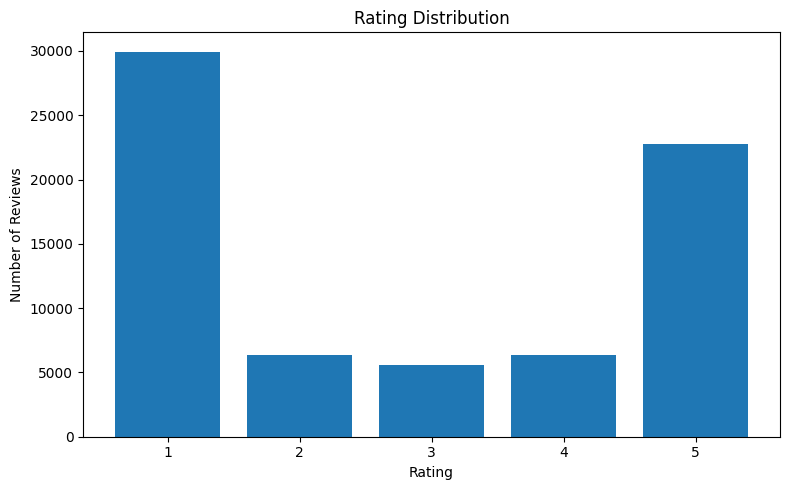

In [6]:
plt.figure(figsize=(8, 5))
plt.bar(rating_counts.index.astype(str), rating_counts.values)
plt.title("Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.tight_layout()

plt.savefig(FIGURES_DIR / "rating_distribution.png", dpi=300)
plt.show()

In [7]:
sentiment_counts = df["sentiment"].value_counts()
sentiment_counts

sentiment
Negative    36334
Positive    29121
Neutral      5539
Name: count, dtype: int64

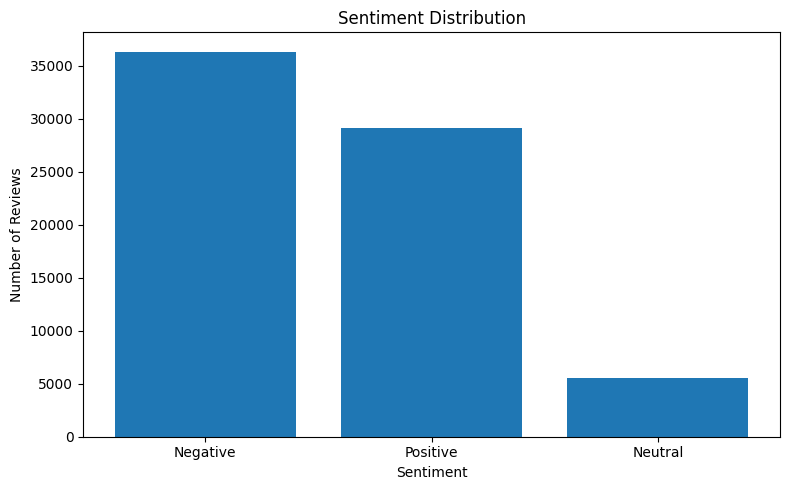

In [8]:
plt.figure(figsize=(8, 5))
plt.bar(sentiment_counts.index, sentiment_counts.values)
plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()

plt.savefig(FIGURES_DIR / "sentiment_distribution.png", dpi=300)
plt.show()

In [9]:
app_counts = df["app_name"].value_counts()
app_counts

app_name
Hive                    10681
ScottishPower            9069
ChargePoint              8081
EDF                      7850
British Gas              6034
PlugShare                5556
OVO Energy               4752
Octopus Energy           4673
Shell                    4402
Electrify America        2864
Tesla                    2058
Zapmap                   1653
Octopus Electroverse     1421
IONITY                    595
Pod Point                 494
E.ON Next Home            267
E.ON Myline               241
Fastned                   187
Vattenfall InCharge       116
Name: count, dtype: int64

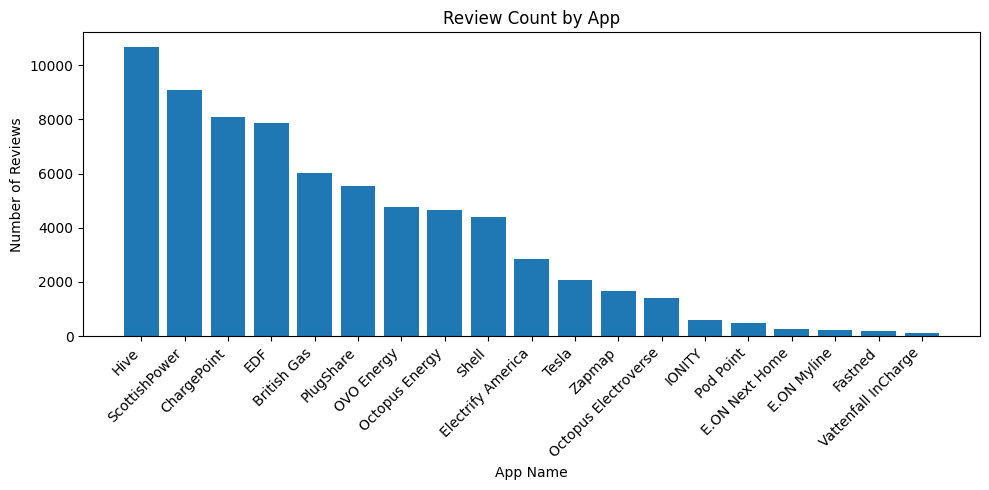

In [10]:
plt.figure(figsize=(10, 5))
plt.bar(app_counts.index, app_counts.values)
plt.title("Review Count by App")
plt.xlabel("App Name")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig(FIGURES_DIR / "review_count_by_app.png", dpi=300)
plt.show()

In [11]:
avg_rating_by_app = (
    df.groupby("app_name")["rating"]
    .mean()
    .sort_values(ascending=False)
)

avg_rating_by_app

app_name
PlugShare               4.064615
Octopus Electroverse    3.665728
Fastned                 3.647059
Shell                   3.540891
Octopus Energy          3.364434
Tesla                   3.192906
Zapmap                  3.192377
ChargePoint             2.973147
ScottishPower           2.796119
EDF                     2.598981
Electrify America       2.596020
OVO Energy              2.590067
IONITY                  2.522689
Hive                    2.211310
Vattenfall InCharge     1.956897
E.ON Next Home          1.857678
British Gas             1.722241
E.ON Myline             1.684647
Pod Point               1.587045
Name: rating, dtype: float64

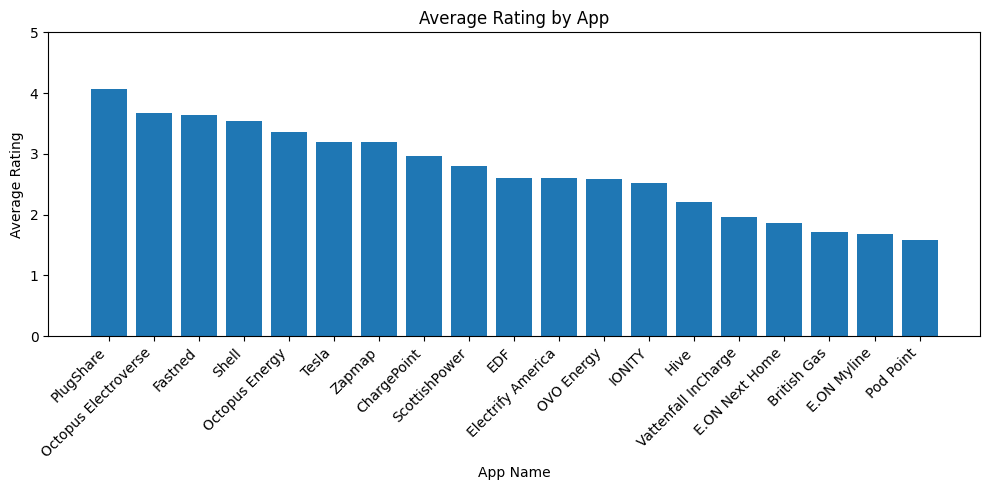

In [12]:
plt.figure(figsize=(10, 5))
plt.bar(avg_rating_by_app.index, avg_rating_by_app.values)
plt.title("Average Rating by App")
plt.xlabel("App Name")
plt.ylabel("Average Rating")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, 5)
plt.tight_layout()

plt.savefig(FIGURES_DIR / "average_rating_by_app.png", dpi=300)
plt.show()

In [13]:
df[["word_count", "clean_word_count"]].describe()

,word_count,clean_word_count
count,70994.000000,70994.000000
mean,29.262135,15.967927
std,26.822017,13.906054
min,2.000000,1.000000
25%,10.000000,6.000000
50%,20.000000,11.000000
75%,39.000000,21.000000
max,538.000000,278.000000


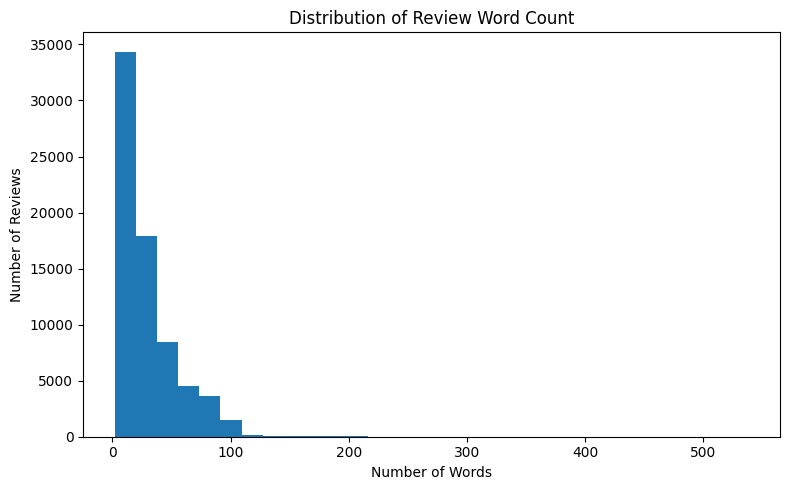

In [14]:
plt.figure(figsize=(8, 5))
plt.hist(df["word_count"], bins=30)
plt.title("Distribution of Review Word Count")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")
plt.tight_layout()

plt.savefig(FIGURES_DIR / "review_word_count_distribution.png", dpi=300)
plt.show()

In [15]:
length_by_sentiment = (
    df.groupby("sentiment")["clean_word_count"]
    .mean()
    .sort_values(ascending=False)
)

length_by_sentiment

sentiment
Negative    19.562256
Neutral     18.803575
Positive    10.943958
Name: clean_word_count, dtype: float64

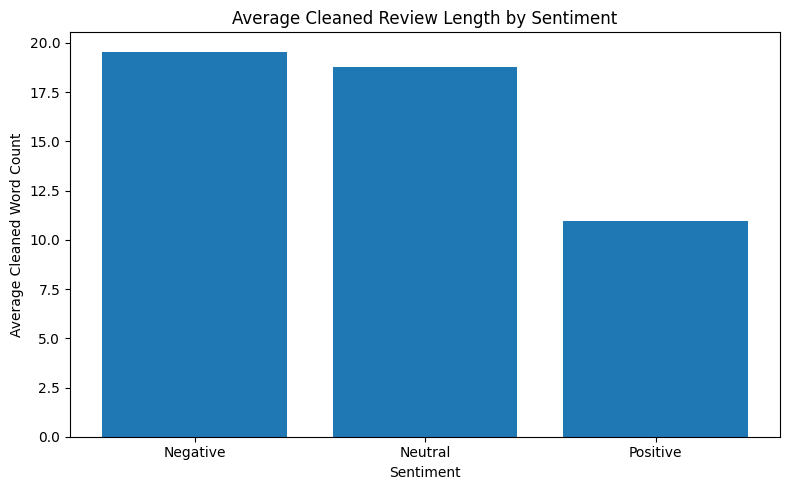

In [16]:
plt.figure(figsize=(8, 5))
plt.bar(length_by_sentiment.index, length_by_sentiment.values)
plt.title("Average Cleaned Review Length by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Average Cleaned Word Count")
plt.tight_layout()

plt.savefig(FIGURES_DIR / "average_review_length_by_sentiment.png", dpi=300)
plt.show()

In [17]:
def get_top_words(text_series, top_n=20):
    vectorizer = CountVectorizer(
        max_features=1000,
        stop_words="english",
        ngram_range=(1, 1)
    )

    word_matrix = vectorizer.fit_transform(text_series)
    word_counts = word_matrix.sum(axis=0).A1

    words_df = pd.DataFrame({
        "word": vectorizer.get_feature_names_out(),
        "count": word_counts
    })

    return words_df.sort_values("count", ascending=False).head(top_n)

In [18]:
positive_words = get_top_words(
    df[df["sentiment"] == "Positive"]["clean_review_text"],
    top_n=20
)

positive_words

,word,count
47,app,13392
239,easy,8325
944,use,7417
355,great,4906
351,good,3973
122,charging,3574
986,work,3060
121,charger,2919
834,station,2513
894,time,2285


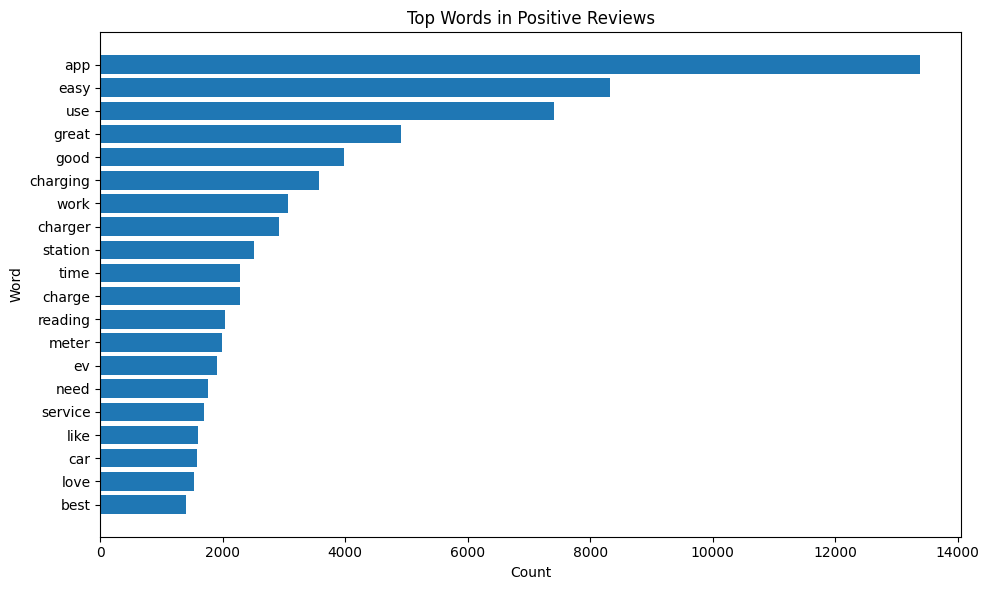

In [19]:
plt.figure(figsize=(10, 6))
plt.barh(positive_words["word"][::-1], positive_words["count"][::-1])
plt.title("Top Words in Positive Reviews")
plt.xlabel("Count")
plt.ylabel("Word")
plt.tight_layout()

plt.savefig(FIGURES_DIR / "top_positive_words.png", dpi=300)
plt.show()

In [20]:
negative_words = get_top_words(
    df[df["sentiment"] == "Negative"]["clean_review_text"],
    top_n=20
)

negative_words

,word,count
36,app,30741
885,time,7479
986,work,7341
510,meter,5501
927,update,5488
933,use,4910
7,account,4493
540,new,3857
663,reading,3779
125,charge,3671


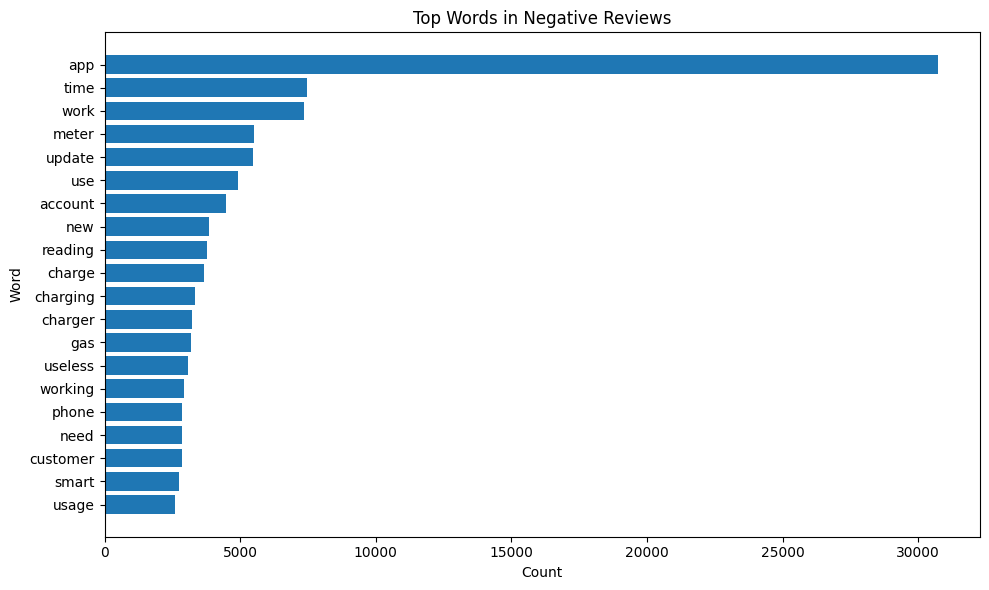

In [21]:
plt.figure(figsize=(10, 6))
plt.barh(negative_words["word"][::-1], negative_words["count"][::-1])
plt.title("Top Words in Negative Reviews")
plt.xlabel("Count")
plt.ylabel("Word")
plt.tight_layout()

plt.savefig(FIGURES_DIR / "top_negative_words.png", dpi=300)
plt.show()

In [22]:
eda_summary = pd.DataFrame({
    "metric": [
        "total_reviews",
        "unique_apps",
        "average_rating",
        "average_word_count",
        "positive_reviews",
        "negative_reviews",
        "neutral_reviews"
    ],
    "value": [
        len(df),
        df["app_name"].nunique(),
        round(df["rating"].mean(), 2),
        round(df["word_count"].mean(), 2),
        (df["sentiment"] == "Positive").sum(),
        (df["sentiment"] == "Negative").sum(),
        (df["sentiment"] == "Neutral").sum()
    ]
})

eda_summary

,metric,value
0,total_reviews,70994.00
1,unique_apps,19.00
2,average_rating,2.80
3,average_word_count,29.26
4,positive_reviews,29121.00
5,negative_reviews,36334.00
6,neutral_reviews,5539.00


In [23]:
eda_summary.to_csv("../reports/eda_summary.csv", index=False)
rating_counts.to_csv("../reports/rating_distribution.csv")
sentiment_counts.to_csv("../reports/sentiment_distribution.csv")
avg_rating_by_app.to_csv("../reports/average_rating_by_app.csv")
positive_words.to_csv("../reports/top_positive_words.csv", index=False)
negative_words.to_csv("../reports/top_negative_words.csv", index=False)

print("EDA summary files saved successfully.")

EDA summary files saved successfully.
